First, we install necessary libraries.

In [1]:
%pip install -r lib/requirements.txt

Note: you may need to restart the kernel to use updated packages.


In [2]:
# Code imports
from lib.opt_types import *
from lib.utils import *

# First Order Methods - 30 points

Following the regularized formulation in [Part 1, equation (2)](Part%201%20-%20Theory.ipynb#eq-regularized-estimator), we now consider binary logistic regression. Here $f$ is the average negative log-likelihood over the $n$ samples, as implemented by the helper function. We solve:

<a id="eq-binary-objective"></a>

$$
	\mathbf{x}^\star=\arg\min_{\mathbf{x} \in \mathbb{R}^p} f_\mu(\mathbf{x}), \qquad f_\mu(\mathbf{x}) := f(\mathbf{x}) + \frac{\mu}{2}\|\mathbf{x}\|_2^2.
\tag{3}
$$

The optimality condition of [(3)](#eq-binary-objective) is

<a id="eq-optimality"></a>

$$
\nabla f_\mu({\mathbf x}^\star) = \frac{1}{n}\sum_{i=1}^n -b_i \sigma(-b_i \cdot \mathbf{a}_i^T\mathbf{x}^\star)\mathbf{a}_i + \mu \mathbf{x}^\star = 0. \tag{4}
$$

Thanks to convexity, condition [(4)](#eq-optimality) is in fact the necessary and sufficient condition for $\mathbf x^\star$ to be optimal.
We can equivalently write this condition as

<a id="eq-fixed-point"></a>

$$
\mathbf x^\star = {\mathbf x}^\star - \mathbf{B} \nabla f_\mu({\mathbf x}^\star) \tag{5}
$$

for any symmetric, positive definite matrix $\mathbf{B}$. 
This is a fixed-point formulation of [(3)](#eq-binary-objective), which will be used to develop first-order methods.


Notice that choosing $\mathbf{B} = \alpha \mathbb{I}$ with $\alpha > 0$ in the formulation [(5)](#eq-fixed-point) suggests that the gradient descent method can be used to solve [(3)](#eq-binary-objective). 

In this part, you will implement different variants of the gradient descent algorithm. 


### Code structure:

A `Function` is a type that has the following attributes:

```python
@dataclass
class Function:
    f              # The function that is being minimized
    grad           # The gradient of the function
    minimum        # The minimum value of the function
    strng_cvx      # The strong convexity constant, if it admits one
    lips_grad      # The smoothness constant, if it admits one
```

For a provided `Function` object `f`:
- You can evaluate the function at a point `x` by simply writing `f(x)`.
- You can evaluate the gradient at a point `x` by writing `f.grad(x)`.
- You can get the smoothness constant by writing `f.lips_grad`.
- You can get the strong convexity constant by writing `f.strng_cvx`



The helper provides the objective $f_\mu$ as the object `f` and an initial point `x_zero`.

In [3]:
from lib.part_one import f, x_zero

The provided `test` function runs a method on the strongly convex quadratic $x \mapsto \frac{1}{2}x^\top M x$, starting from $x_0 = \begin{bmatrix} 100.0& 100.0 \end{bmatrix}$. By default, it runs 100 iterations. For example, after implementing `GD`, run

```python
test(GD)
```

<div class="alert alert-block alert-success">
<b>Run the cells in order.</b> Later cells use variables defined in earlier cells.
</div>

### Variants of Gradient Descent

Now you will implement various methods to iteratively improve the initial guess `x_zero`.

__(a)__ (2 points) The main ingredients of the gradient descent algorithm are the descent direction (the negative gradient) and the step-size $\alpha_k$. 
In this part, we consider the gradient descent algorithm with constant step-size ${1}/{L}$, i.e., $\alpha_k = {1}/{L}$ for any $k = 0,1,...$ where $L$ is the gradient-Lipschitz constant of the function `f`. 

Gradient Descent, as an iterative scheme, only tracks the current iterate `x_k` and the step size `alpha_k`. We store them both in a state variable that holds both these attributes:

In [4]:
@dataclass
class GD_state(OptState):
    x_k: Vector
    alpha_k: float

Given a function `f` and a state at some iteration $k$, recall how GD updates the state and fill in the following cell:

In [5]:
def GD_update(f, state):
    x_k, alpha_k = state
    x_next = x_k - alpha_k * f.grad(x_k)
    return GD_state(x_k=x_next, alpha_k=alpha_k)


Having defined the `GD_update` which updates a given state, we now need to initialize the state. Fill in the cell below, recalling that you are given an initial guess `x_zero`, and the fact that we are using a fixed step size corresponding to the smoothness constant of `f`.

In [6]:
def GD_initialize(f, x_zero):
    x_k = x_zero
    alpha_k = 1/f.lips_grad
    return GD_state(x_k, alpha_k)


With the initialization and the update scheme specified, we define the algorithm in the cell below:

In [7]:
GD = OptAlgorithm(name="GD", init_state = GD_initialize, state_update = GD_update)

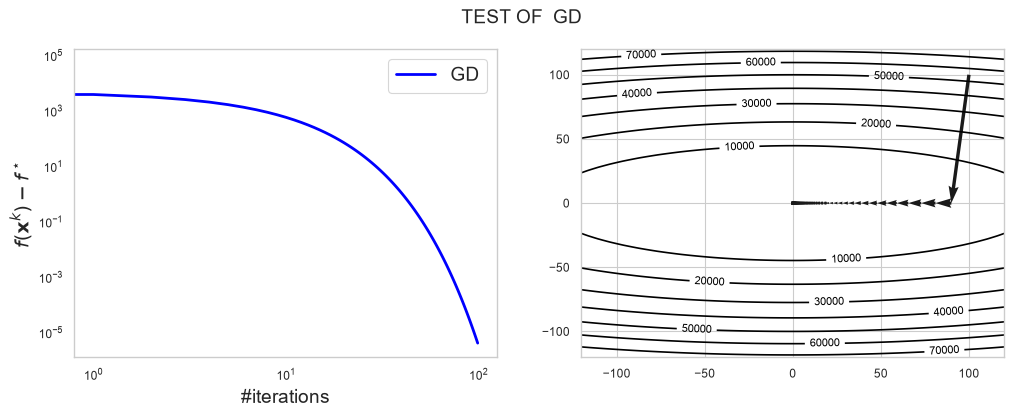

In [8]:
test(GD)

We now notice that the objective function is strongly convex. Therefore, we can select the constant step-size $\alpha$ as $2/(L+\mu)$ to get a faster convergence rate. We call this algorithm `GDstr`.

Both `GD` and `GDstr` have the same state update but only differ in the stepsize they use. Implement this variant of the gradient descent method by completing the code:

In [9]:
def GDstr_initialize(f, x_zero):
    x_k = x_zero
    alpha_k = 2/(f.lips_grad+f.strng_cvx)
    return GD_state(x_k, alpha_k)

GDstr = OptAlgorithm(name="GDstr", init_state=GDstr_initialize, state_update=GD_update)


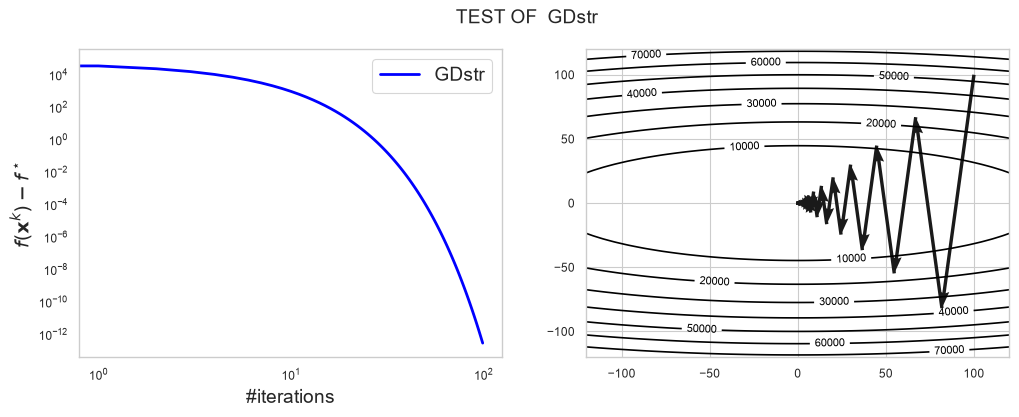

In [10]:
test(GDstr)

__(b-1)__ (1.5 points) We can accelerate the above gradient descent algorithm with the following scheme ($t_0=1$):

$$
\begin{array}{ll}
\mathbf{x}^{k+1} &:=  \mathbf{y}^k - \alpha_k\nabla{f_\mu}(\mathbf{y}^k),\\
t_{k+1} &:= \frac{1}{2}(1 + \sqrt{1 + 4t_k^2})\\
\mathbf{y}^{k+1} &:= \mathbf{x}^{k+1} + \frac{t_k-1}{t_{k+1}}\big(\mathbf{x}^{k+1} - \mathbf{x}^k\big).
\end{array}
$$

Implement this algorithm with constant step-size $\alpha = 1/L$, by completing the missing parts of the following cells.

First we define the state that the algorithm updates at each iteration:

In [11]:
@dataclass
class AGD_state(OptState):
    x_k: Vector
    y_k: Vector
    t_k: float
    alpha_k: float

Given this `state` and a function `f` to optimize, write the update step of accelerated gradient descent:

In [12]:
def AGD_update(f, state):
    x_k, y_k, t_k, alpha_k = state
    next_x_k = y_k - alpha_k * f.grad(y_k)
    next_t_k = (1+np.sqrt(1 + 4 * t_k * t_k))/2
    next_y_k = next_x_k + ((t_k - 1)/next_t_k)*(next_x_k - x_k)
    next_alpha_k = 1/f.lips_grad
    return AGD_state(next_x_k, next_y_k, next_t_k, next_alpha_k)


Define the initial state of AGD in the cell below:

In [13]:
def AGD_initialize(f, x_zero):
    alpha_k = 1/f.lips_grad
    x_k = x_zero
    y_k = x_k
    t_k = 1

    return AGD_state(x_k,y_k,t_k,alpha_k)


We have all the necessary ingredients to define the optimization algorithm in the following cell:

In [14]:
AGD = OptAlgorithm(name="AGD", init_state=AGD_initialize, state_update=AGD_update)

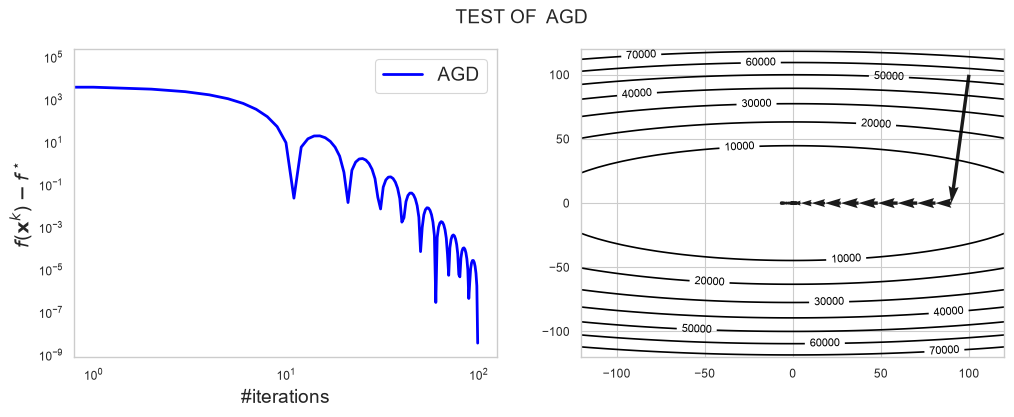

In [15]:
test(AGD)

__(b-2)__ (1 point)

Note that the objective function is strongly convex. Therefore, we can use the accelerated gradient algorithm for strongly convex objectives to converge faster. This variant can be summarized as follows:

$$
\left\{
\begin{aligned}
\mathbf{x}^{k+1} &:= \mathbf{y}^k - \alpha_k \nabla f_\mu(\mathbf{y}^k),\\
\mathbf{y}^{k+1} &:= \mathbf{x}^{k+1} + m\big(\mathbf{x}^{k+1} - \mathbf{x}^k\big).
\end{aligned}
\right.
$$
 
Implement this variant of the accelerated gradient method by completing the following cells. Try different values of $m$ and comment on what should be the best value for this constant. Do the practical results follow the theory?

In [16]:
@dataclass
class AGDstr_state(OptState):
    x_k: Vector
    y_k: Vector
    alpha_k: float
    m_strongcvx: float

In [17]:
def AGDstr_update(f, state):
    x_k, y_k, alpha_k, m_strongcvx = state
    next_x_k = y_k - alpha_k * f.grad(y_k)
    next_y_k = next_x_k + m_strongcvx * (next_x_k - x_k)
    return AGDstr_state(next_x_k, next_y_k, alpha_k, m_strongcvx)


def AGDstr_initialize(f, x_zero):
    L = f.lips_grad
    mu = f.strng_cvx
    m_strongcvx = (np.sqrt(L) - np.sqrt(mu))/ (np.sqrt(L) + (np.sqrt(mu)))
    x_k = x_zero
    y_k = x_k
    alpha_k = 1/L
    return AGDstr_state(x_k,y_k,alpha_k,m_strongcvx)


In [18]:
AGDstr = OptAlgorithm(name="AGDstr", init_state=AGDstr_initialize, state_update=AGDstr_update)

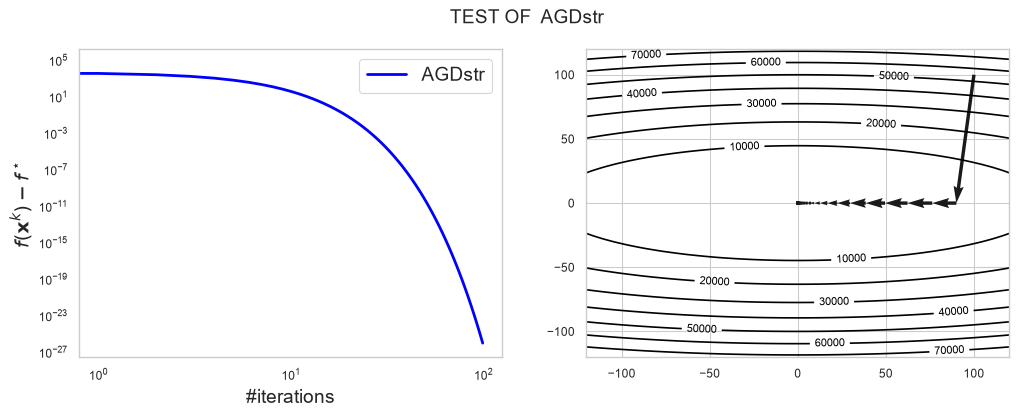

In [19]:
test(AGDstr)

test with m = 0


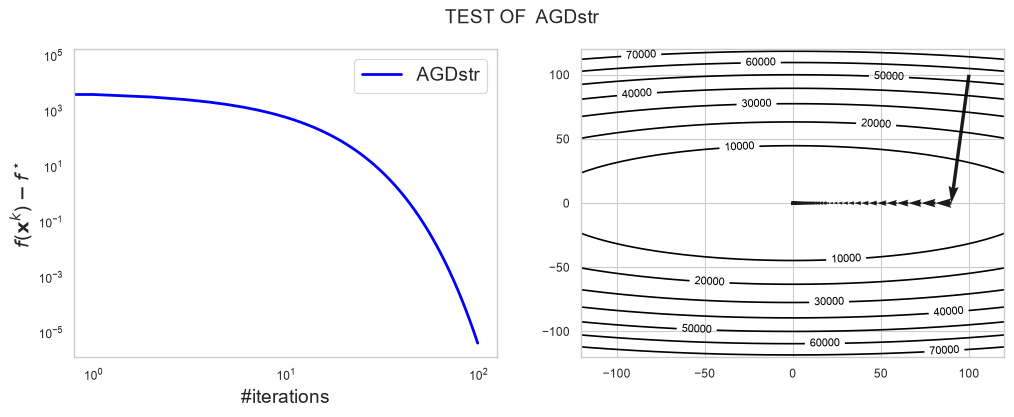

test with m = 0.5


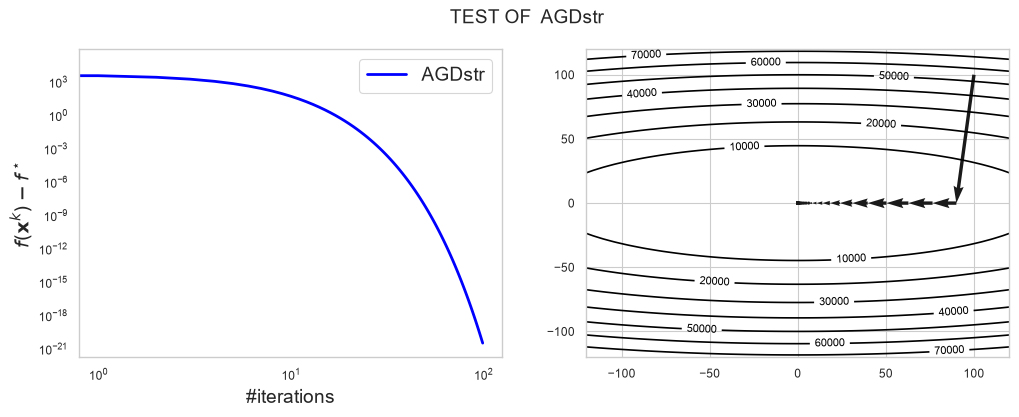

test with m = 0.9


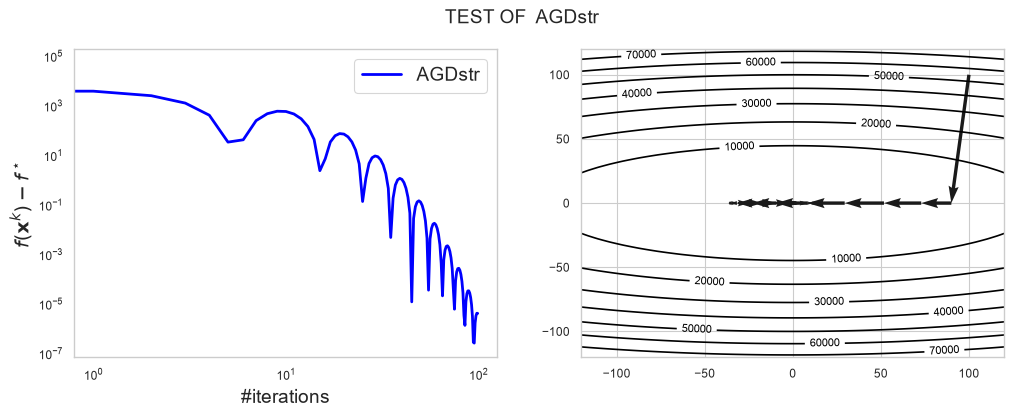

test with m = 1


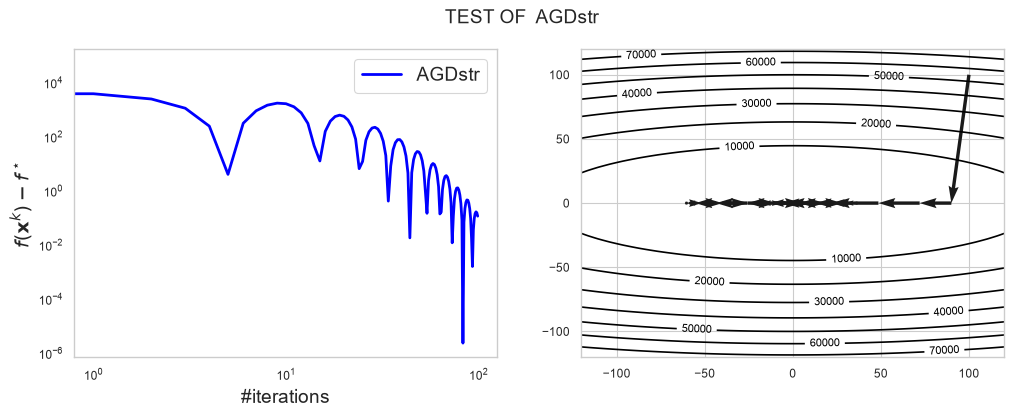

test with m = 2


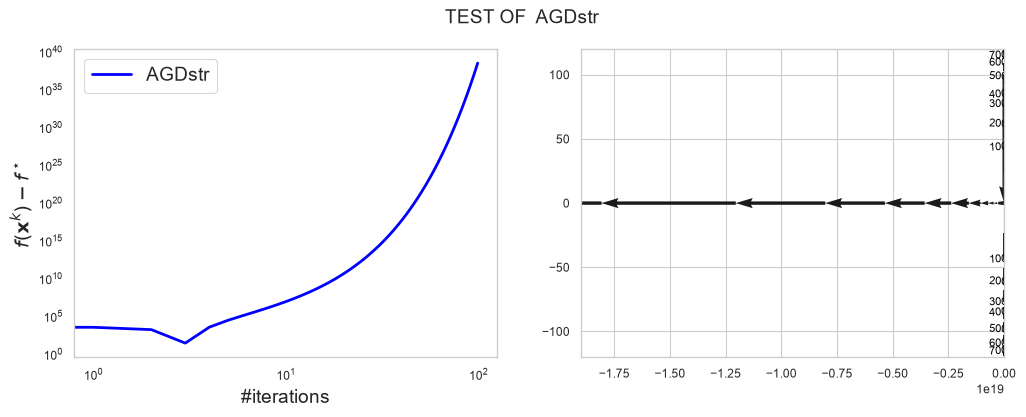

test with m = 4


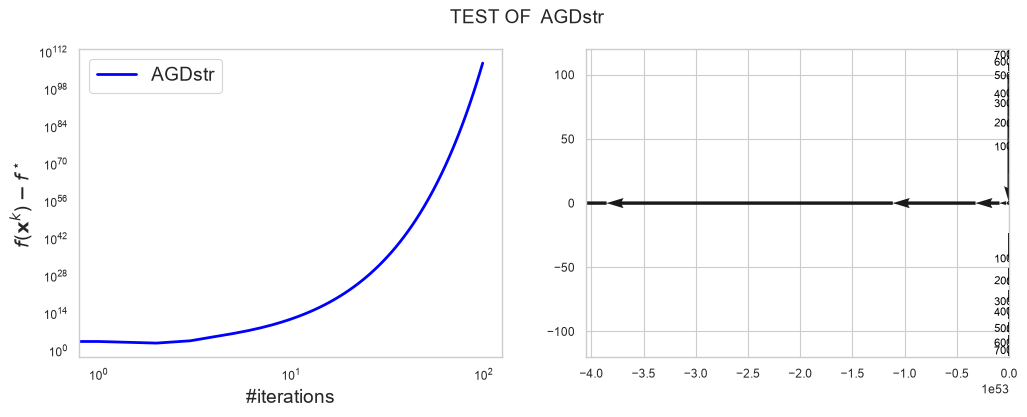

test with m = theoretical


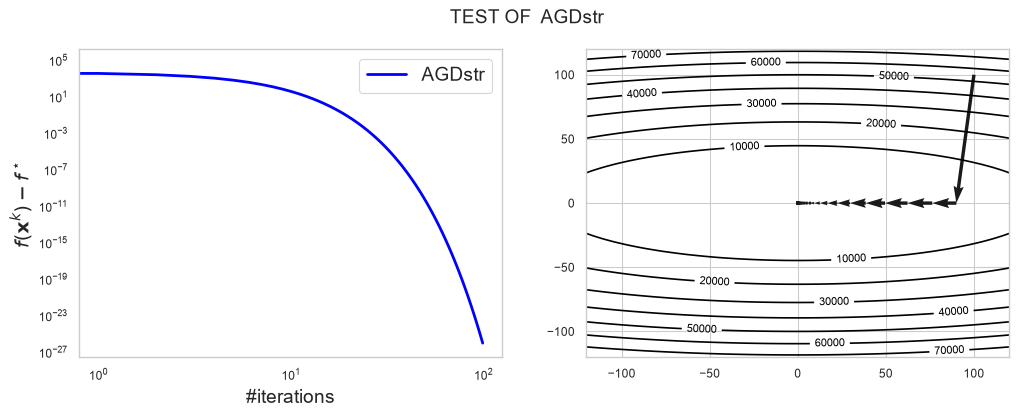

In [20]:
for val in [0, 0.5, 0.9, 1, 2, 4, None]:
    def AGDstr_m_initialize(f, x_zero, m=val):
        if m is None:
            m = (np.sqrt(f.lips_grad) - np.sqrt(f.strng_cvx)) / (np.sqrt(f.lips_grad) + np.sqrt(f.strng_cvx))
        return AGDstr_state(x_zero, x_zero, 1 / f.lips_grad, m)
    print(f"test with m = {'theoretical' if val is None else val}")
    test(OptAlgorithm(name="AGDstr", init_state=AGDstr_m_initialize, state_update=AGDstr_update))

We tested $m \in \{0, 0.5, 0.9, 1, 2, 4\}$ and the theoretical value $m^\star = \frac{\sqrt{L}-
\sqrt{\mu}}{\sqrt{L}+\sqrt{\mu}} = \frac{\sqrt{10}-1}{\sqrt{10}+1} \approx 0.52$ of the test quadratic 
($L=10$, $\mu=1$, $\kappa=10$). After 100 iterations:
- $m=0$ is plain gradient descent with step $1/L$: monotone but slow ($f-f^\star\approx 
4\cdot10^{-6}$).
- $m=0.5$, close to $m^\star$, is much faster ($\approx 4\cdot10^{-21}$).
- $m=m^\star$ is the fastest ($\approx 10^{-26}$).
- $m=0.9$ overshoots: the objective oscillates and ends around $4\cdot10^{-6}$.
- $m=1$ does not converge ($\approx10^{-1}$).
- $m=2$ and $m=4$ diverge.

The best value is the theoretical one, as predicted: with $m^\star=\frac{\sqrt\kappa-1}
{\sqrt\kappa+1}$,\
AGDstr converges linearly with rate $1-1/\sqrt{\kappa}$ instead of the $1-1/\kappa$ 
of gradient descent. Too little momentum behaves like GD; too much makes the iterates oscillate, and 
$m\ge1$ prevents convergence. The practical results follow the theory.

__(c)__ (5 points) We can obtain better performance by considering a line search procedure, which adapts the step-size $\alpha_k$ to the local geometry. 
The line-search strategy to determine the step-size $\alpha_k$ for the standard GD algorithm,
$\mathbf{x}^{k+1}=\mathbf{x}^k-\alpha_k\nabla f_\mu(\mathbf{x}^k),$
is the following: 

Initialize $L_{-1}=L$. At iteration $k\geq0$, use the current iterate $\mathbf{x}^k$ and descent direction $\mathbf{d}^k=-\nabla f_\mu(\mathbf{x}^k)$:

* At each iteration, set $L_{k,0} = \frac{1}{2}L_{k-1}$, where $k$ is the iteration counter. 
* Starting at $i=0$ and increasing $i$ as needed, find the minimum integer $i \geq 0$ that satisfies $f_\mu\left(\mathbf{x}^k + \frac{1}{2^i L_{k,0}} \mathbf{d}^k\right) \leq f_\mu(\mathbf{x}^k) -\frac{1}{2^{i+1} L_{k,0}} \|\mathbf{d}^k\|^2$.
* Set $L_k = {2^i L_{k,0}}$ and use the step-size $\alpha_k := \frac{1}{L_k}$ to take the accepted gradient step.

Complete the missing parts in order to implement gradient descent with line-search.

In [21]:
@dataclass
class LS_GD_state(OptState):
    x_k: Vector
    L_k: float


In [22]:
def LS_GD_update(f, state):
    x_k, L_pre = state
    d_k = -f.grad(x_k)
    L_k0 = L_pre / 2
    i = 0
    flag = True
    while flag:
        L_k = (2**i)*L_k0
        alpha_k = 1/L_k
        if f(x_k + alpha_k * d_k) <= f(x_k) - (np.linalg.norm(d_k)**2)/(2*L_k):
            flag = False
        i += 1
    return LS_GD_state(x_k + alpha_k * d_k,L_k)

def LS_GD_initialize(f, x_zero):
    
    return LS_GD_state(x_zero, f.lips_grad)


In [23]:
LS_GD = OptAlgorithm(name="LS_GD", init_state = LS_GD_initialize, state_update=LS_GD_update )

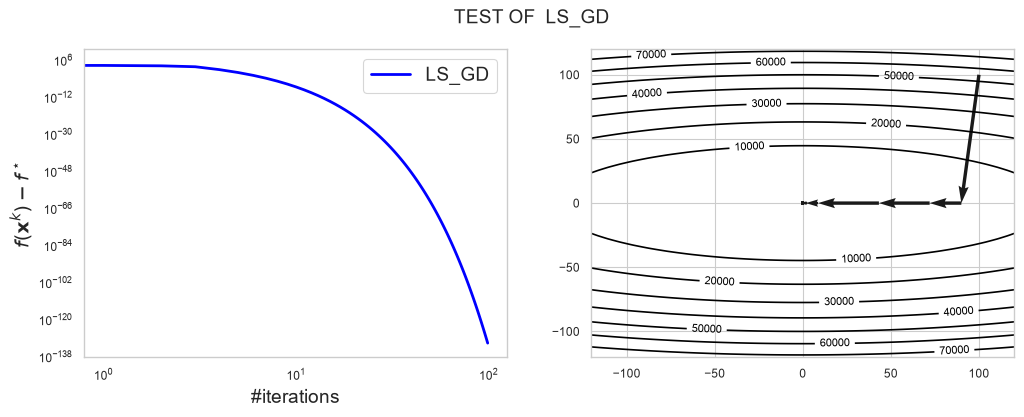

In [24]:
test(LS_GD)

We now incorporate a line-search enhancement to the accelerated gradient method implemented in (b-1). At iteration $k$, 
we have the current iterate $\mathbf{x}^k$ together with an _intermediate variable_ $\mathbf{y}^k$ and its corresponding direction $\mathbf{d}^k=-\nabla f_\mu(\mathbf{y}^k)$. **Note that the intermediate variable is then used in the gradient step and hence the line-search will be performed on it to determine the step-size**.


Perform a line-search strategy with respect to $\mathbf{y}^k$ and direction $\mathbf{d}^k$ to determine the step-size $\alpha_k$ as follows:

Initialize $L_{-1}=L$. Then, for $k\geq0$:

* At each iteration, set $L_{k,0} = \frac{1}{2}L_{k-1}$, where $k$ is the iteration counter. 
* Starting at $i=0$ and increasing $i$ as needed, find the minimum integer $i \geq 0$ that satisfies $f_\mu\left(\mathbf{y}^k + \frac{1}{2^i L_{k,0}} \mathbf{d}^k\right) \leq f_\mu(\mathbf{y}^k) -\frac{1}{2^{i+1} L_{k,0}} \|\mathbf{d}^k\|^2$.
* Set $L_k = {2^i L_{k,0}}$ and use the step-size $\alpha_k := \frac{1}{L_k}$.
 
Update the next iterations:
$$
\left\{
\begin{aligned}
\mathbf{x}^{k+1} &:= \mathbf{y}^k - \alpha_k \nabla f_\mu(\mathbf{y}^k),\\
t_{k+1} &:= \frac{1}{2}\left(1 + \sqrt{1 + 4\frac{L_k}{L_{k-1}}t_k^2}\right),\\
\mathbf{y}^{k+1} &:= \mathbf{x}^{k+1} + \frac{t_k-1}{t_{k+1}}\big(\mathbf{x}^{k+1} - \mathbf{x}^k\big).
\end{aligned}
\right.
$$

Complete the missing parts in order to implement accelerated gradient descent with line-search.

In [25]:
@dataclass
class LS_AGD_state(OptState):
    x_k: Vector
    y_k: Vector
    t_k: float
    L_k: float


In [26]:
def LS_AGD_update(f, state):
    x_k, y_k, t_k, L_pre = state
    d_k = -f.grad(y_k)
    L_k0 = L_pre / 2
    i = 0
    flag = True
    while flag:
        L_k = (2 ** i) * L_k0
        alpha_k = 1 / L_k
        x_next = y_k + alpha_k * d_k
     
        if f(x_next)<= f(y_k) - (np.linalg.norm(d_k) ** 2) / (2 * L_k):
            flag = False
        i+=1
    t_next = (1 + np.sqrt(1 + 4 * (L_k / L_pre) * t_k ** 2)) / 2
    y_next = x_next + ((t_k - 1) / t_next) * (x_next - x_k)

    return LS_AGD_state(x_next,y_next,t_next,L_k)
        

def LS_AGD_initialize(f, x_zero):
    x_k = x_zero
    y_k = x_k
    t_k = 1
    L_k = f.lips_grad
    return LS_AGD_state(x_k, y_k, t_k, L_k)


In [27]:
LS_AGD = OptAlgorithm(name="LS_AGD", init_state=LS_AGD_initialize, state_update=LS_AGD_update )

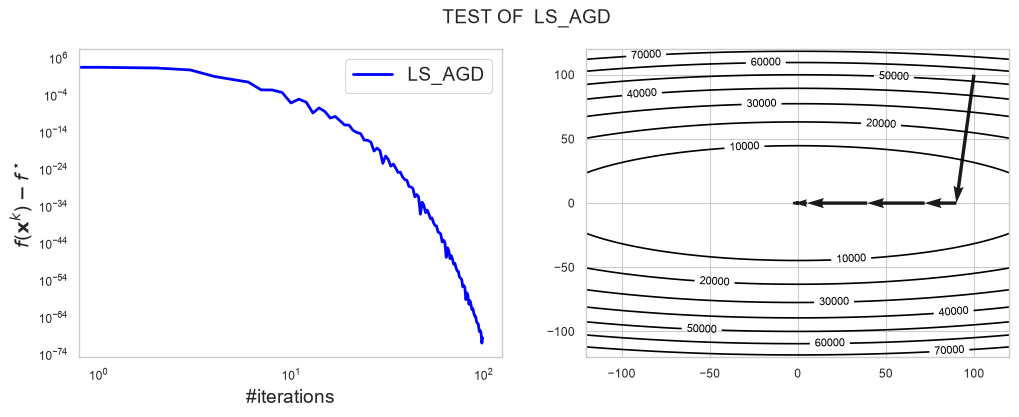

In [28]:
test(LS_AGD)

__(d)__ (3 points) The accelerated gradient method need not decrease the objective at every iteration: we may have $f_\mu(\mathbf{x}^{k+1})>f_\mu(\mathbf{x}^k)$ at some iterations.
To prevent such behavior, we can use the so-called adaptive restart strategy. 
In short, this strategy can be explained as follows: 
At each iteration, whenever $\mathbf{x}^{k+1}$ is computed, we evaluate $f_\mu(\mathbf{x}^{k+1})$ and compare it with $f_\mu(\mathbf{x}^k)$: 

* If $f_\mu(\mathbf{x}^k) < f_\mu(\mathbf{x}^{k+1})$, restart the iteration, i.e., recompute $\mathbf{x}^{k+1}$ by setting $\mathbf{y}^{k} := \mathbf{x}^{k}$ and $t_{k} := 1$;
* Otherwise, let the algorithm continue.


This strategy requires the evaluation of the function value at each iteration, which increases the computational complexity of the overall algorithm. 

Implement the adaptive restart strategy which uses the function values for the accelerated gradient algorithm with constant step-size $\alpha_k=1/L$ 
by completing the function:

In [29]:
@dataclass
class AGDR_state(AGD_state):
    pass


In [30]:
def AGDR_update(f, state):
    x_k, y_k, t_k, alpha_k = state
    x_next = y_k - alpha_k * f.grad(y_k)

    if f(x_next) > f(x_k):
        y_k = x_k
        t_k = 1

        x_next = y_k - alpha_k * f.grad(y_k)
    t_next = (1 + np.sqrt(1 + 4 * t_k ** 2)) / 2
    y_next = x_next + ((t_k - 1) / t_next) * (x_next - x_k)

    return AGDR_state(x_next,y_next,t_next,alpha_k)
AGDR_initialize = AGD_initialize

In [31]:
AGDR = OptAlgorithm(name="AGDR", init_state = AGDR_initialize, state_update=AGDR_update)

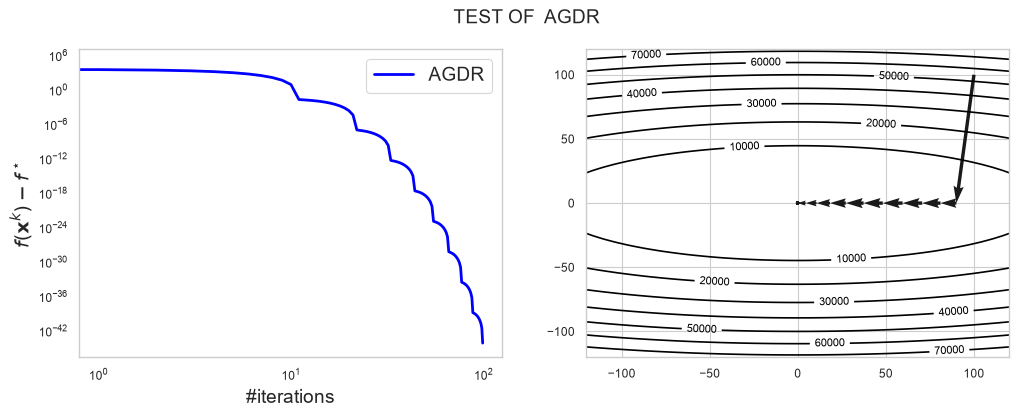

In [32]:
test(AGDR)

__(e)__ (Self-study, 0 points)
Combine line search, acceleration, and objective-based restart by completing `LS_AGDR_update`.

**Hint:** If the proposed step increases the objective, reset $\mathbf{y}^k=\mathbf{x}^k$ and $t_k=1$. Repeat the line search from this reset point and recompute the gradient step before updating the momentum.


In [33]:
@dataclass 
class LS_AGDR_state(LS_AGD_state):
    pass


In [34]:
def LS_AGDR_update(f, state):
    x_k, y_k, t_k, L_pre = state
    d_k = -f.grad(y_k)
    L_k0 = L_pre / 2
    i = 0
    while True:
        L_k = (2 ** i) * L_k0
        x_next = y_k + d_k / L_k
        if f(x_next) <= f(y_k) - (np.linalg.norm(d_k) ** 2) / (2 * L_k):
            break
        i += 1

    if f(x_next) > f(x_k):
        y_k = x_k
        t_k = 1
        d_k = -f.grad(y_k)
        L_k0 = L_pre / 2
        i = 0
        flag = True
        while flag:
            L_k = (2 ** i) * L_k0
            x_next = y_k + d_k / L_k
            if f(x_next) <= f(y_k) - (np.linalg.norm(d_k) ** 2) / (2 * L_k):
                flag= False
            i += 1

    t_next = (1 + np.sqrt(1 + 4 * (L_k / L_pre) * t_k ** 2)) / 2
    y_next = x_next + ((t_k - 1) / t_next) * (x_next - x_k)
    return LS_AGDR_state(x_next, y_next, t_next, L_k)

LS_AGDR_initialize = LS_AGD_initialize

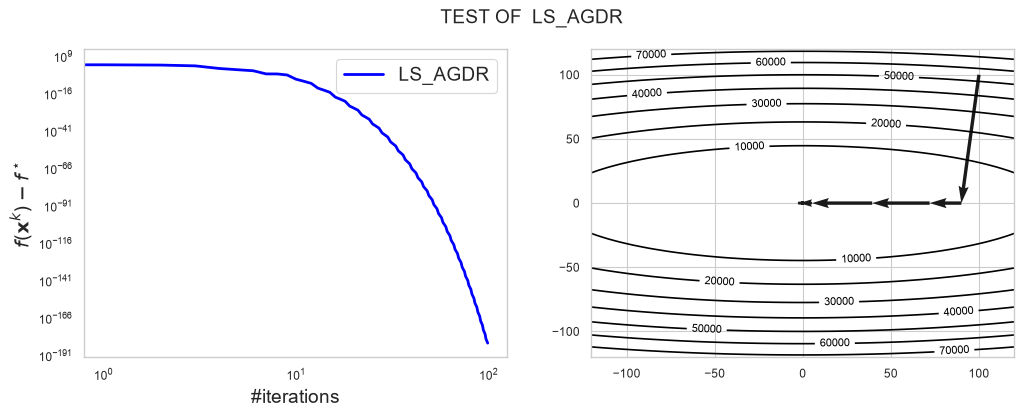

In [35]:
LS_AGDR = OptAlgorithm(name="LS_AGDR", init_state=LS_AGDR_initialize, state_update=LS_AGDR_update)

test(LS_AGDR)

__(f)__ (4 points) We can also apply an optimization technique that does not exploit the knowledge of the Lipschitz constant, and instead adapts to the local geometry by making use of past gradient information. This scalar AdaGrad variant divides the step size by the square root of the accumulated squared gradient norms. Starting with $Q_0 = 0$ it iterates as follows:

$$
\left\{\begin{array}{ll}
Q_{k+1} &{\!\!\!\!}= Q_k + \|\nabla f_\mu(\mathbf{x}^k)\|^2 \\
\mathbf{H}_k &{\!\!\!\!}= (\sqrt{Q_{k+1}} + \delta) I \\
\mathbf{x}^{k+1} &{\!\!\!\!}= \mathbf{x}^k - \alpha \mathbf{H}_k^{-1} \nabla f_\mu(\mathbf{x}^k)
\end{array}\right.
$$

Complete the missing parts in the function AdaGrad in order to implement the above adaptive gradient method using $\alpha = 1$, $\delta = 10^{-5}$.

In [36]:
@dataclass
class AdaGrad_state(OptState):
    x_k: Vector
    Q_k: float


In [37]:
def AdaGrad_update(f, state):
    x_k, Q_k = state
    g_k = f.grad(x_k)
    Q_next = Q_k + np.linalg.norm(g_k) ** 2
    x_next = x_k - g_k / (np.sqrt(Q_next) + 1e-5)
    return AdaGrad_state(x_next, Q_next)

def AdaGrad_initialize(f, x_zero):
    return AdaGrad_state(x_zero, 0.0)


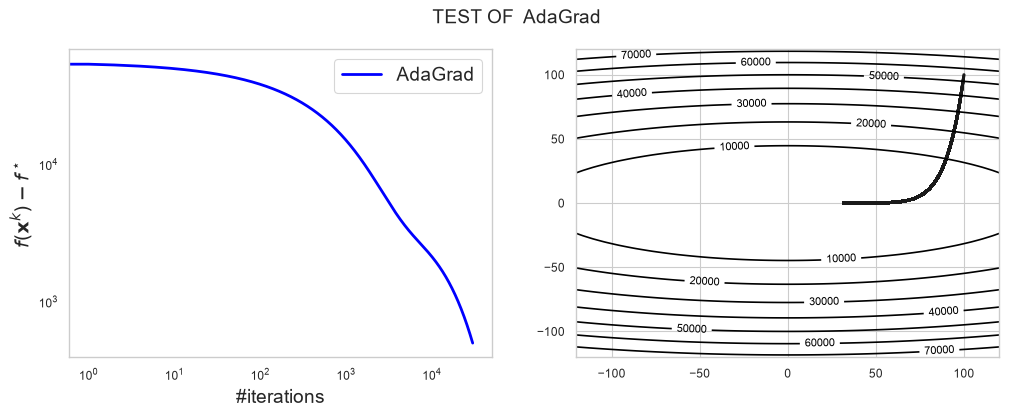

In [38]:
AdaGrad = OptAlgorithm(name="AdaGrad", init_state=AdaGrad_initialize, state_update=AdaGrad_update)
test(AdaGrad, maxiter=30000)

__(g)__ (2.5 points) Another famous adaptive optimization method is called the ADAptive Moment estimation algorithm, also known as ADAM, 

$$
\left\{\begin{array}{ll}
\mathbf{g}_k &{\!\!\!\!} = \nabla f_\mu(\mathbf{x}^{k}) \\
\mathbf{m}_{k+1} &{\!\!\!\!} = \beta_1 \mathbf{m}_{k} + (1-\beta_1)\mathbf{g}_k \ \textrm{$\leftarrow$ Momentum}\\
\mathbf{v}_{k+1} &{\!\!\!\!} = \beta_2 \mathbf{v}_{k} + (1-\beta_2)\mathbf{g}_k^2 \ \textrm{$\leftarrow$ Adaptive term}\\
\hat{\mathbf{m}}_{k+1} &{\!\!\!\!} = \mathbf{m}_{k+1} / (1-\beta_1^{k+1})\\
\hat{\mathbf{v}}_{k+1} &{\!\!\!\!} = \mathbf{v}_{k+1} / (1-\beta_2^{k+1}) \ \textrm{$\leftarrow$ Scaling for removing bias}\\
\mathbf{H}_{k+1} &{\!\!\!\!} \ = \sqrt{\hat{\mathbf{v}}_{k+1}} + \epsilon \\
\mathbf{x}^{k+1} &{\!\!\!\!} = \mathbf{x}^k - \alpha \hat{\mathbf{m}}_{k+1} / \mathbf{H}_{k+1}
\end{array}\right.
$$

Note that all operations shown above, when applied to vectors, are applied element-wise. In particular, $\mathbf{g}_k^2$ is a vector of the same size as $\mathbf{g}_k$ where each element is squared.

Complete the missing parts in the cells below in order to implement the above adaptive gradient method using $\alpha = 0.1$, $\beta_1 = 0.9$, $\beta_2 = 0.999$ and $\epsilon = 10^{-8}$.

It has been shown that ADAM can fail to converge to the global minimum of a convex problem. The authors provided a variant of ADAM, called AMSgrad in order to fix this convergence issue. However, in practice it is not clear which method performs best. (You are not required to implement this method, but advised to have a look at it for personal interest).

In [39]:
@dataclass
class ADAM_state(OptState):
    x_k: Vector
    m_k: Vector
    v_k: Vector
    k: int


In [40]:
def ADAM_update(f, state):
    x_k, m_k, v_k, k = state
    alpha = 0.1
    beta_1 = 0.9
    beta_2 = 0.999
    epsilon = 1e-8
    g_k = f.grad(x_k)
    m_next = beta_1 * m_k + (1 - beta_1) * g_k
    v_next = beta_2 * v_k + (1 - beta_2) * (g_k ** 2)
    step = k + 1
    m_hat = m_next / (1 - beta_1 ** step)
    v_hat = v_next / (1 - beta_2 ** step)
    x_next = x_k - alpha * m_hat / (np.sqrt(v_hat) + epsilon)
    return ADAM_state(x_next, m_next, v_next, step)

def ADAM_initialize(f, x_zero):
    zeros = np.zeros_like(x_zero)
    return ADAM_state(x_zero, zeros, zeros, 0)
    

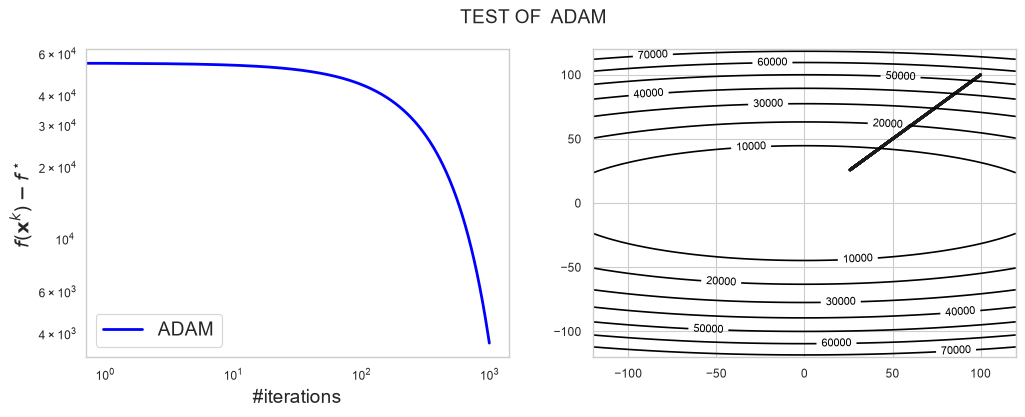

In [41]:
ADAM = OptAlgorithm(name="ADAM", init_state=ADAM_initialize, state_update=ADAM_update)

test(ADAM, maxiter=1000)

## Schedule-Free Optimizer
Schedule-Free learning replaces the momentum of an underlying optimizer with a combination of interpolation and averaging. In the case of gradient descent, the basic Schedule-Free update is:

$$
\begin{align*}
y_{t} & = (1-\beta)z_{t} + \beta x_{t},\\
z_{t+1} & =z_{t}-\gamma\nabla f_\mu(y_{t}),\\
x_{t+1} & =\left(1-\frac{1}{t+1}\right)x_{t}+\frac{1}{t+1}z_{t+1},
\end{align*}
$$

Evaluate the objective at the averaged iterates $x_t$. The iterates $z_t$ receive the gradient updates, while gradients are evaluated at $y_t$. The updates to $z$ correspond to the underlying optimizer, in this case a simple gradient step.

Schedule-Free learning uses a constant learning rate together with averaging. Its performance depends on the problem and chosen parameters. Only $x_t$ and $z_t$ need to be stored between iterations, since $y_t$ can be computed from them.

Initialize $x_0=z_0$ at `x_zero` and start at $t=0$. Use the constant step size $\gamma=1/L$ and $\beta=0.5$. For the test quadratic, $L=10$, so $\gamma=0.1$.

**(a)** (1 point) Complete the initializer and update for the Schedule-Free optimizer.


In [42]:
@dataclass
class Scheduler_free_state(OptState):
    x_k: Vector
    z_k: Vector
    t_k: int


In [43]:
def Scheduler_free_update(f, state):
    x_k, z_k, t_k = state
    beta = 0.5
    gamma = 1 / f.lips_grad
    y_k = (1 - beta) * z_k + beta * x_k
    z_next = z_k - gamma * f.grad(y_k)
    t_next = t_k + 1
    x_next = (1 - 1 / t_next) * x_k + (1 / t_next) * z_next
    return Scheduler_free_state(x_next, z_next, t_next)

def Scheduler_free_initialize(f, x_zero):
    return Scheduler_free_state(x_zero, x_zero.copy(), 0)


**(b)** (1 point) Run your experiment and discuss why the algorithm is referred to as a schedule-free optimizer. You may refer to [The Road Less Scheduled](https://arxiv.org/abs/2405.15682).

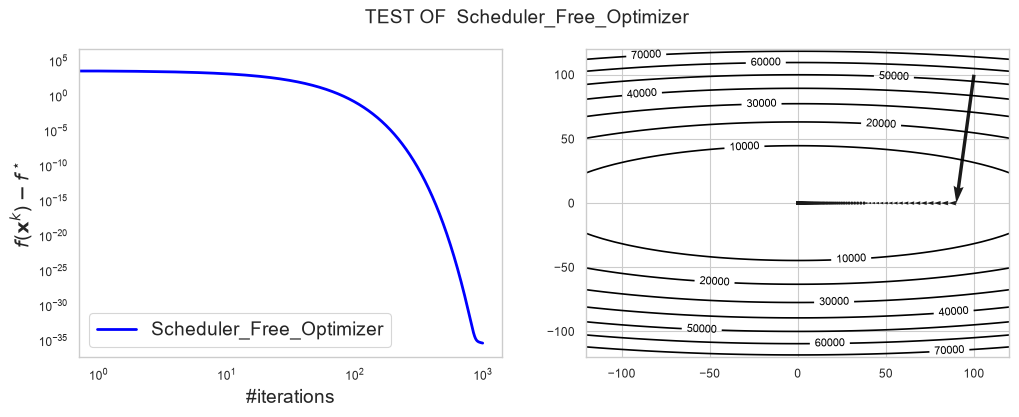

In [44]:
SFO = OptAlgorithm(name="Scheduler_Free_Optimizer", init_state=Scheduler_free_initialize, state_update=Scheduler_free_update)

test(SFO, maxiter=1000)

The method is called schedule free because it needs no learning rate schedule and, in particular, no 
stopping time $T$ fixed in advance. Usual practice decays the step size (linear, cosine, $1/\sqrt t$) 
along a schedule that depends on $T$. \
Here $\gamma=1/L$ stays constant, and the role of the decay is 
played by two mechanisms:\
 the online uniform average: $x_{t+1}=(1-\frac{1}{t+1})x_t+\frac{1} \
{t+1}z_{t+1}$, which gives the new iterate weight $1/(t+1)$, \
and the interpolation $y_t=(1-\beta)z_t+\beta x_t$ where the gradient is evaluated.\
 Defazio et al. (2024) show that this matches 
tuned schedules without knowing $T$ (an "anytime" method). On the test quadratic the averaged iterate 
$x_t$ decreases steadily to about $10^{-35}$ in 1000 iterations without tuning. On the logistic problem 
it is slower than GD, because its step $1/L$ is limited by the very large global smoothness constant.

## Polyak’s Heavy Ball (PHB) Method

Polyak’s Heavy Ball (PHB) method accelerates gradient descent by adding momentum, modeling a ball rolling over the objective landscape with friction. The continuous-time form is

$$
\ddot{\mathbf{x}} = -a\,\nabla f_\mu(\mathbf{x}) - b\,\dot{\mathbf{x}},
$$

where $a$ controls attraction to the minimum and $b$ provides damping.

The discrete update is

$$
\mathbf{x}_{k+1} = \mathbf{x}_k - \alpha\,\nabla f_\mu(\mathbf{x}_k) + \beta\,(\mathbf{x}_k - \mathbf{x}_{k-1}),
$$

with step size $\alpha$ and momentum $\beta$.

For a strongly convex quadratic with Hessian eigenvalues in $[\mu,L]$, the classical parameter choice is

$$
\alpha = \frac{4}{(\sqrt{L}+\sqrt{\mu})^2}, \qquad 
\beta = \left(\frac{\sqrt{\kappa}-1}{\sqrt{\kappa}+1}\right)^2, \quad \kappa = \frac{L}{\mu},
$$

For these quadratics, the asymptotic convergence factor is

$$
\rho=\frac{\sqrt{\kappa}-1}{\sqrt{\kappa}+1}.
$$

This quadratic result does not guarantee convergence with the same parameters for every smooth, strongly convex objective. On our logistic regression problem, treat this parameter choice as an experiment; momentum can also cause oscillations.

We'll implement PHB with a state that stores the current iterate, the previous iterate, and the scalars $\alpha$ and $\beta$.

**(a)** (1 point) Complete the initializer and update for Polyak’s Heavy Ball optimizer.


In [45]:
@dataclass
class PHB_state(OptState):
    x_k: Vector
    x_pre: Vector
    alpha_k: float
    beta_k: float


In [46]:
def PHB_update(f, state):
    x_k, x_pre, alpha_k, beta_k = state
    x_next = x_k - alpha_k * f.grad(x_k) + beta_k * (x_k - x_pre)
    return PHB_state(x_next, x_k, alpha_k, beta_k)


def PHB_initialize(f, x_zero):
    L = f.lips_grad
    mu = f.strng_cvx
    alpha = 4 / (np.sqrt(L) + np.sqrt(mu)) ** 2
    kappa = L / mu
    beta = ((np.sqrt(kappa) - 1) / (np.sqrt(kappa) + 1)) ** 2
    return PHB_state(x_zero, x_zero.copy(), alpha, beta)


**(b)** (1 point) Test Polyak’s Heavy Ball optimizer.

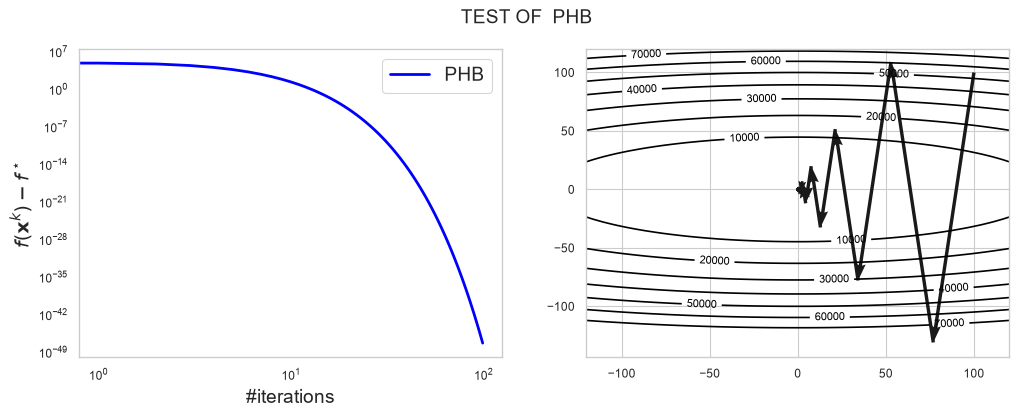

In [47]:
PHB = OptAlgorithm(name="PHB", init_state=PHB_initialize, state_update=PHB_update)

test(PHB)


## NAG-Free Adaptive Acceleration

Here, NAG-Free denotes an adaptive variant of Nesterov’s method that uses line search and local curvature estimates to choose its step size and momentum, without restarts.

Initialize $\mathbf{x}_0=\mathbf{y}_0=$ `x_zero`. Initialize the stored smoothness estimate to `f.lips_grad` and the stored strong-convexity estimate to `f.strng_cvx`; use $1$ and $0$, respectively, if the corresponding value is unavailable or nonpositive. Initialize momentum using the rule below and cache $\nabla f_\mu(\mathbf{y}_0)$.

At iteration $k$, use the following rules:

1. **Line search (`_backtracking_L`).** Starting from half the stored smoothness estimate, double the trial value until
   $$
   f_\mu\!\left(\mathbf{y}_k-\frac{1}{L_k}\nabla f_\mu(\mathbf{y}_k)\right)
   \leq f_\mu(\mathbf{y}_k)-\frac{1}{2L_k}\|\nabla f_\mu(\mathbf{y}_k)\|_2^2.
   $$
   Allow at most 40 doublings; raise `RuntimeError` if the condition still fails. Here $L_k$ denotes the accepted value. Take the gradient step $\mathbf{x}_{k+1}=\mathbf{y}_k-\nabla f_\mu(\mathbf{y}_k)/L_k$.

2. **Local curvature (`_estimate_mu`).** Set $\mathbf{s}_k=\mathbf{x}_{k+1}-\mathbf{x}_k$ and $\mathbf{r}_k=\nabla f_\mu(\mathbf{x}_{k+1})-\nabla f_\mu(\mathbf{x}_k)$. Use
   $$
   \widehat\mu_k=
   \begin{cases}
   \dfrac{\mathbf{s}_k^\top\mathbf{r}_k}{\|\mathbf{s}_k\|_2^2},
      & \|\mathbf{s}_k\|_2^2>0\text{ and }\mathbf{s}_k^\top\mathbf{r}_k>0,\\
   0, & \text{otherwise}.
   \end{cases}
   $$

3. **Momentum (`_momentum_from_L_mu`).** Use
   $$
   a_k=
   \begin{cases}
   \dfrac{\sqrt{L_k}-\sqrt{\widehat\mu_k}}{\sqrt{L_k}+\sqrt{\widehat\mu_k}},
      & L_k>0\text{ and }\widehat\mu_k>0,\\
   0, & \text{otherwise},
   \end{cases}
   \qquad
   \mathbf{y}_{k+1}=\mathbf{x}_{k+1}+a_k(\mathbf{x}_{k+1}-\mathbf{x}_k).
   $$

Store the new iterate, extrapolated point, gradient at that point, and the new estimates $L_k$, $\widehat\mu_k$, and $a_k$ for the next iteration.

Local curvature estimates are not necessarily valid global bounds. This variant should therefore be evaluated experimentally; the accelerated convergence guarantee for AGDstr does not automatically apply to it.

**(a)** (1 point) Complete the cells below to define the state, update rule, initializer, and algorithm object.


In [48]:
@dataclass
class NAGFree_state(OptState):
    x_k: Vector
    y_k: Vector
    g_k: Vector
    L_k: float
    mu_k: float
    a_k: float


In [49]:
def _backtracking_L(f, y, g, L_prev):
    L_k = L_prev / 2.0
    f_y = f(y)
    g_norm_sq = float(np.sum(g * g))

    if g_norm_sq == 0.0:
        return float(L_prev/2)

    for _ in range(41):
        x_next = y - g / L_k
        if f(x_next) <= f_y - g_norm_sq / (2.0 * L_k):
            return float(L_k)

        L_k *= 2.0

    raise RuntimeError(
        "Backtracking line search failed to find a valid smoothness estimate."
    )

def _estimate_mu(x_prev, x_cur, g_prev, g_cur):
    s = x_cur - x_prev
    r = g_cur - g_prev
    s_norm_sq = float(np.sum(s * s))
    curvature = float(np.sum(s * r))
    if s_norm_sq > 0.0 and curvature > 0.0:
        return curvature / s_norm_sq
    return 0.0

def _momentum_from_L_mu(L_k, mu_k):
    if L_k > 0.0 and mu_k > 0.0:
        sqrt_L = np.sqrt(L_k)
        sqrt_mu = np.sqrt(mu_k)
        return float((sqrt_L - sqrt_mu) / (sqrt_L + sqrt_mu))
    return 0.0

def NAGFree_update(f, state):
    x_k, y_k, g_k, L_prev, _, _ = state

    L_k = _backtracking_L(f, y_k, g_k, L_prev)
    x_next = y_k - g_k / L_k
    g_x_k = f.grad(x_k)
    g_x_next = f.grad(x_next)

    mu_k = _estimate_mu(x_k, x_next, g_x_k, g_x_next)
    a_k = _momentum_from_L_mu(L_k, mu_k)

    y_next = x_next + a_k * (x_next - x_k)
    g_y_next = f.grad(y_next)
    return NAGFree_state(x_next, y_next, g_y_next, L_k, mu_k, a_k)

def NAGFree_initialize(f, x_zero):
    if f.lips_grad is None or f.lips_grad <= 0:
        L_0 = 1.0
    else:
        L_0 = f.lips_grad

    if f.strng_cvx is None or f.strng_cvx <= 0:
        mu_0 = 0.0
    else:
        mu_0 = f.strng_cvx

    x_0 = x_zero.copy()
    y_0 = x_zero.copy()
    g_0 = f.grad(y_0)
    a_0 = _momentum_from_L_mu(L_0, mu_0)
    return NAGFree_state(x_0, y_0, g_0, L_0, mu_0, a_0)


**(b)** (1 point) Test the NAG-Free adaptive acceleration.

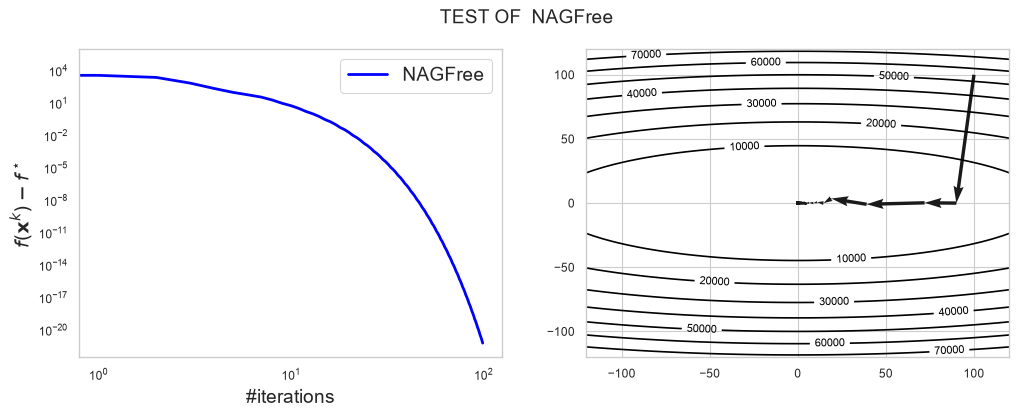

In [50]:
NAGFree = OptAlgorithm(name="NAGFree", init_state=NAGFree_initialize, state_update=NAGFree_update)

test(NAGFree)


## Running the methods - 5 points


We now apply these methods to binary logistic regression, modeling the probability that a basketball shot is successful.

Our data originates from motion tracking data captured by the NBA during the 2015-2016 season.

<img width=50% src='lib/golden_state_shots.png'/>

We consider the `3376` shots made by the Golden State Warriors. The label $b_i$ indicates whether shot $i$ was successful. The five features in $\mathbf{a}_i$ are the shooter’s x- and y-coordinates, distance to the basket, and the minutes and seconds remaining in the quarter.

**(a)** (1 point) Run the following cell to compare the methods you have implemented on the logistic loss:

NAGFree: 100%|██████████| 5000/5000 [00:04<00:00, 1160.64it/s]


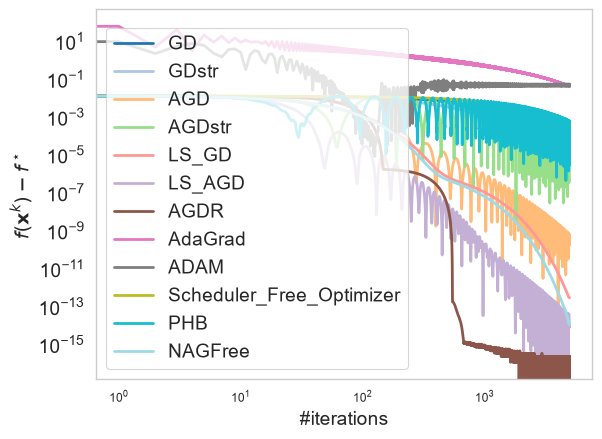

In [51]:
from lib.part_one import f, x_zero, train_accuracy

methods = [GD, GDstr, AGD, AGDstr, LS_GD, LS_AGD, AGDR, AdaGrad, ADAM,SFO, PHB, NAGFree]
plot(methods, f, x_zero, max_iteration=5000, palette="tab20")

**(b)** (2 points) Compare the methods in the plot and discuss whether their observed convergence agrees with the theory.

The plot mostly matches what we expect from theory, especially when we consider the condition number of the problem and the difference between global and local smoothness.

GD, GDstr, and SFO are really slow. Even though the function is strongly convex (so we should get linear convergence in theory), the global constant $L$ is very large ($L \approx 4.4 \cdot 10^{4}$) and $\mu$ is very small ($\mu = 10^{-3}$). This makes the condition number $\kappa = L/\mu \approx 4.4 \cdot 10^{7}$ huge and forces a tiny step size $1/L$, so after $5000$ iterations these methods are still around $2 \cdot 10^{-5}$ (GD), $5 \cdot 10^{-7}$ (GDstr) and $5 \cdot 10^{-4}$ (SFO).

Adding momentum in AGD, AGDstr, and PHB speeds up convergence a lot compared to GD, which agrees with the theoretical improvement from $\mathcal{O}(\kappa)$ to $\mathcal{O}(\sqrt{\kappa})$. We also see the classic oscillations where the loss is not monotonic because momentum overshoots. Here AGD gets to a lower error (around $10^{-10}$) than AGDstr and PHB, which keep oscillating until the end (roughly between $10^{-8}$ and $10^{-4}$ for AGDstr, and between $10^{-7}$ and $10^{-3}$ for PHB). The reason is that their momentum is fixed using the global $L$ and $\mu$: for AGDstr $m = \frac{\sqrt{L}-\sqrt{\mu}}{\sqrt{L}+\sqrt{\mu}} \approx 0.9997$, so there is almost no damping, while near the solution the problem is much better conditioned than the global $\kappa$ suggests and a smaller momentum would work better.

LS_GD and NAGFree use a backtracking line search: instead of the worst-case global $L$, they estimate the local smoothness $L_k$ and can take much larger steps than $1/L$. After $5000$ iterations LS_GD reaches about $3 \cdot 10^{-13}$ and NAGFree about $10^{-14}$, with NAGFree slightly faster thanks to its adaptive momentum.

LS_AGD combines the two ideas, acceleration and line search, and it is the fastest method at the beginning: after $100$ iterations it is already around $2 \cdot 10^{-5}$, while AGD, LS_GD and NAGFree are still around $10^{-3}$, and after $1000$ iterations it is around $10^{-10}$. This agrees with theory, since it has the $\mathcal{O}(1/k^2)$ rate of accelerated methods but uses the local $L_k$ instead of the global $L$. However, there is no restart, so the momentum still makes it oscillate a lot: it reaches $10^{-15}$ only after about $2000$ iterations and then keeps jumping between about $10^{-16}$ and $10^{-13}$.

AGDR does not use a line search: it keeps the constant step $1/L$ of AGD and adds the function value restart. Resetting the momentum whenever $f_\mu$ increases removes the oscillations of AGD, and near the solution the restarted scheme adapts to the local strong convexity. AGDR is the best method overall and reaches machine precision ($\approx 10^{-16}$) in about $700$ iterations, before LS_AGD even without the line search. This suggests that on this problem the oscillations caused by momentum are a bigger issue than the choice of the step size.

Lastly, AdaGrad and ADAM do not work well here and end around $4$–$5 \cdot 10^{-2}$, which is even worse than the starting point. They are mainly meant for stochastic optimization with noisy gradients rather than full-batch problems. For AdaGrad, the first steps with $\alpha = 1$ are way too large for this problem (the error jumps above $10$), and then accumulating the squared gradients makes the step size shrink too fast, so it needs thousands of iterations just to come back down. ADAM gets close to the minimum at the beginning (around $10^{-5}$ after about $120$ iterations), but then the error goes up again and stays around $5 \cdot 10^{-2}$. This is probably because, as the gradients become small, $\mathbf{v}_k$ also becomes small and the effective step $\alpha / \sqrt{\hat{\mathbf{v}}_k}$ grows, pushing the iterates away from the solution. This is the convergence issue of ADAM mentioned above, which AMSgrad fixes by never letting $\mathbf{v}_k$ decrease.


Pick the best performing method and run the following cell to display the training accuracy of your solution:

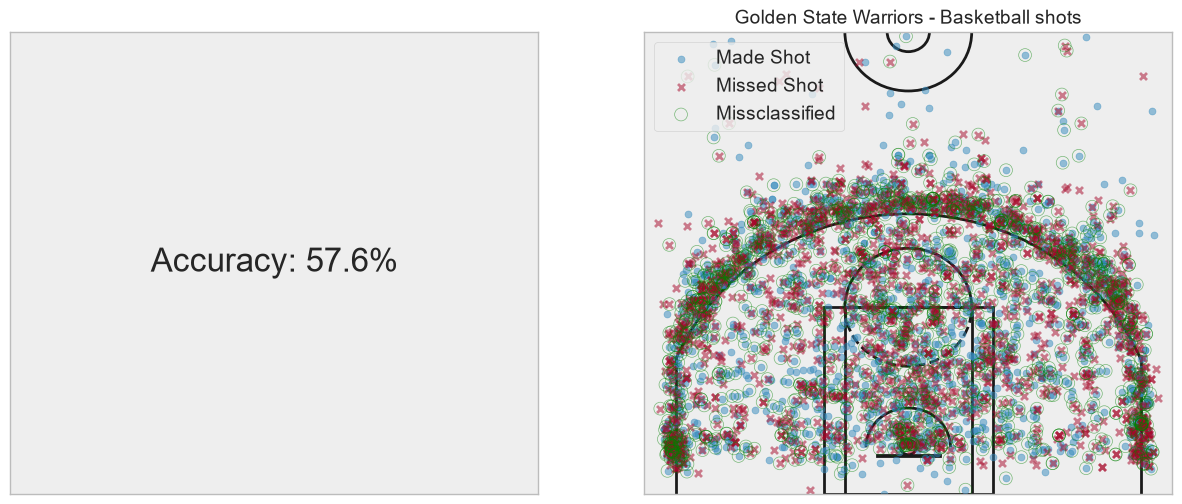

In [52]:
method = AGDR
run_trace = run(method, f, x_zero, 5000)
last_x_k = run_trace.sequence[-1]

train_accuracy(run_trace.sequence[-1])

**(c)** (2 points) Given we have access to as many as `84467` distinct shots from all teams that played in the 2015–2016 season, how could we use them to improve our model? What effect would this have on the computational cost of our deterministic methods?

Having 84,467 shots instead of just 3,376 would help us improve the model in a few ways. Training on a much larger dataset from all teams reduces overfitting and helps the model learn a more general relationship between the features and the shot outcome. With so many samples, we can also properly split the data into training, validation, and test sets (or use cross-validation). This lets us use the validation set to tune the regularization parameter mu and try out new features (like polynomial terms or the shooting angle to the basket), while keeping the test set to check the actual generalization accuracy at the end.

On the other hand, using all the data makes the deterministic methods much more expensive. Since full batch algorithms have to sum over all n samples every time they compute the loss f(x) or the gradient grad f(x), the cost per iteration scales linearly with n, i.e., O(n*d). Going from 3,376 to 84,467 shots increases n by about 25 times, so every single iteration of our deterministic methods becomes roughly 25 times slower. This is even worse for the methods with backtracking line search, because they have to evaluate f(x) multiple times at each step. With a dataset of this size, it would make much more sense to switch to stochastic or mini-batch methods like SGD.

In the next notebook, you will use stochastic methods to reduce the computational cost of a single iteration.